In [1]:
import os, subprocess

# 워드클라우드 설치 (코랩에 없으면)
try:
    import wordcloud
except ImportError:
    subprocess.run(['pip', 'install', '-q', 'wordcloud'])

# 나눔고딕 설치 (코랩용)
NANUM = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if not os.path.exists(NANUM):
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

In [2]:
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 사용할 한글 폰트 찾기 (코랩: 나눔고딕 / 맥: AppleGothic / 윈도우: 맑은 고딕)
font_candidates = [
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    '/System/Library/Fonts/Supplemental/AppleGothic.ttf',
    'C:/Windows/Fonts/malgun.ttf',
    '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
]
font_path = next(p for p in font_candidates if os.path.exists(p))
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지
print('사용 폰트:', font_path)

# 그래프 공통 스타일
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9a9a9a', 'axes.titleweight': 'bold',
    'axes.titlesize': 14, 'figure.dpi': 110,
})

# 그룹별 고정 색상 – 모든 그래프에서 같은 그룹은 같은 색
GROUPS = ['bts', '세븐틴', '트와이스', '블랙핑크', '베이비몬스터', '코르티스']
GROUP_LABEL = {'bts': 'BTS', '세븐틴': '세븐틴', '트와이스': '트와이스',
               '블랙핑크': '블랙핑크', '베이비몬스터': '베이비몬스터', '코르티스': '코르티스'}
GROUP_COLOR = dict(zip(GROUPS, ['#2a78d6', '#eb6834', '#1baf7a',
                                '#e87ba4', '#6250d6', '#008300']))

사용 폰트: /usr/share/fonts/truetype/nanum/NanumGothic.ttf


In [3]:
# 코랩: 왼쪽 파일 탭에 processed_ko.csv 업로드 후 실행
df = pd.read_csv('processed_ko.csv')
df['tokens'] = df['tokens'].apply(json.loads)
df['published_at'] = pd.to_datetime(df['published_at'])
df['year'] = df['published_at'].dt.year

print('문서 수:', len(df))
print('전체 토큰 수:', df['tokens'].str.len().sum())
print('고유 단어 수:', len({t for ts in df['tokens'] for t in ts}))
print('기간:', df['published_at'].min().date(), '~', df['published_at'].max().date())
df[['group', 'title', 'published_at', 'tokens']].head()

문서 수: 1086
전체 토큰 수: 94708
고유 단어 수: 3369
기간: 2017-01-19 ~ 2026-10-13


,group,title,published_at,tokens
0,bts,"[뮤직와치]시국 외면하지않는 아이돌, 방탄소년단 잘되는 이유 있구나",2017-01-23 14:03:27,"[힘, 시기, 생각, 현실, 눈길, 그룹, 알엠, 슈가, 제이홉, 지민, 뷔, 진,..."
1,bts,"방탄소년단, 브랜드평판 1위 탈환 ‘2위 트와이스-3위 엑소’",2017-01-29 09:30:30,"[그룹, 정, 가수, 브랜드, 평판, 정상, 지난해, 순위, 빅뱅, 한국, 기업, ..."
2,bts,"키이스트 일본 자회사 DA, 방탄소년단 일본 매니지먼트 전속계약 체결",2017-02-27 08:03:17,"[일본, 디지털, 가, 그룹, 일본, 매니지먼트, 전속, 계약, 체결, 주식, 회사..."
3,bts,"[단독]방탄소년단 진X지민 ‘안녕하세요’ 출격, 글로벌대세 고민상담 어떨까",2017-02-28 18:44:12,"[글로벌, 대세, 그룹, 알엠, 슈가, 진, 제이홉, 지민, 뷔, 정국, 멤버, 지..."
4,bts,"방탄소년단, 오늘(6일) 스쿨어택 깜짝 이벤트 포착 ‘중학생 팬 심장어택’",2017-03-06 14:57:44,"[그룹, 중학교, 서울, 강서구, 위치, 방문, 학생, 추억, 선사, 컴백, 동시,..."


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


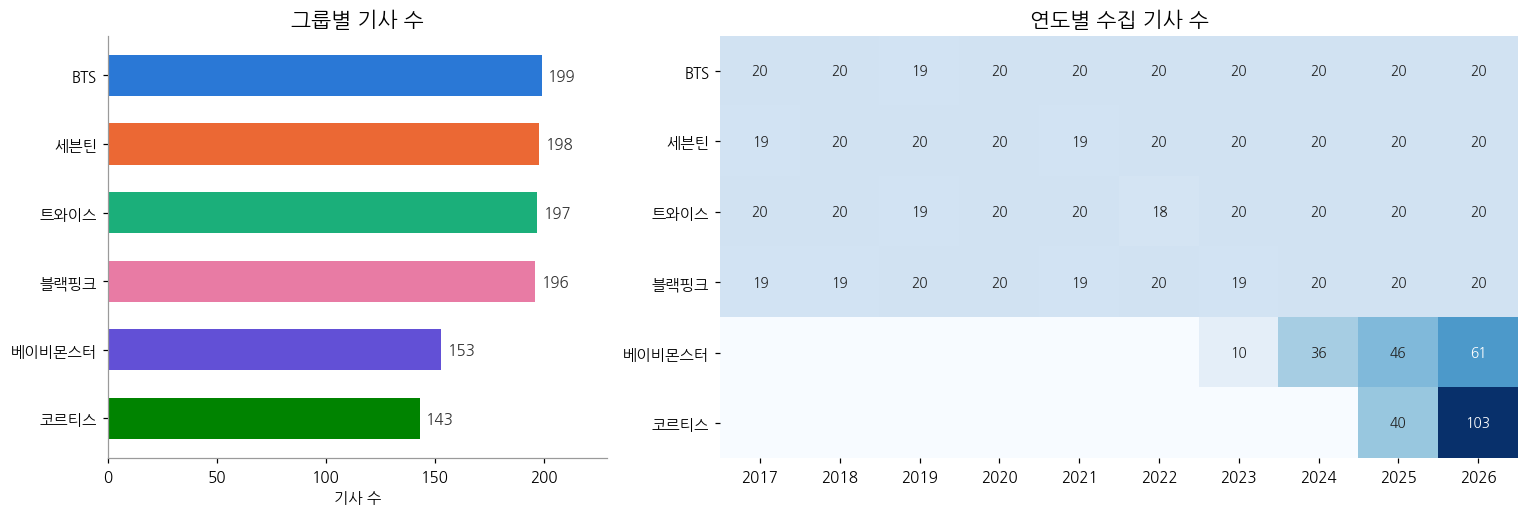

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1.6]})

# (왼쪽) 그룹별 기사 수 – 수평 막대
cnt = df['group'].value_counts().reindex(GROUPS)
ax = axes[0]
ax.barh([GROUP_LABEL[g] for g in GROUPS][::-1], cnt.values[::-1],
        color=[GROUP_COLOR[g] for g in GROUPS][::-1], height=0.6)
for i, v in enumerate(cnt.values[::-1]):
    ax.text(v + 3, i, f'{v}', va='center', fontsize=10, color='#333')
ax.set_title('그룹별 기사 수')
ax.set_xlabel('기사 수')
ax.set_xlim(0, cnt.max() * 1.15)

# (오른쪽) 연도 × 그룹 기사 수 – 히트맵
ct = pd.crosstab(df['group'], df['year']).reindex(GROUPS)
ax = axes[1]
im = ax.imshow(ct.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(ct.columns)), ct.columns)
ax.set_yticks(range(len(GROUPS)), [GROUP_LABEL[g] for g in GROUPS])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j]
        if v:
            ax.text(j, i, v, ha='center', va='center', fontsize=9,
                    color='white' if v > 50 else '#222')
ax.set_title('연도별 수집 기사 수')
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

In [6]:
# 제거 전 상위 30개 확인
before = Counter(t for ts in df['tokens'] for t in ts)
print(before.most_common(30))

[('멤버', 1034), ('앨범', 855), ('팬', 839), ('그룹', 831), ('곡', 759), ('차트', 714), ('무대', 714), ('공개', 693), ('공연', 568), ('데뷔', 568), ('일본', 565), ('음악', 529), ('미국', 497), ('오후', 487), ('공식', 479), ('뮤직비디오', 450), ('발매', 445), ('와이지엔터테인먼트', 439), ('글로벌', 438), ('브랜드', 435), ('아티스트', 433), ('기록', 431), ('가수', 396), ('이번', 377), ('케이팝', 362), ('서울', 356), ('빅히트뮤직', 349), ('일정', 339), ('빌보드', 338), ('진행', 338)]


In [7]:
# 뉴스 기사 문체에서 반복되는 의미 없는 단어 (도메인 불용어)
STOPWORDS = set('''
오후 오전 이번 이날 진행 예정 시간 시작 지난해 올해 이후 모습 게재 공개 발표 공식
일정 개최 참석 기대 관심 생각 다양 분위기 감사 준비 대표 사진 기자 소식 당시
최근 이어 가운데 한편 통해 위해 대한 관련 자신 모두 현재 정도 처음 다음 마지막
오늘 내일 어제 이상 이하 가장 함께 중구 서울 뷰 수 등 것 때 중 날 해 전 후 속
'''.split())

# 한 글자지만 의미가 분명한 단어는 유지 (멤버 이름 뷔·진 포함)
KEEP_ONE_CHAR = {'팬', '곡', '팀', '춤', '쇼', '돔', '뷔', '진'}

def clean(tokens):
    return [t for t in tokens
            if t not in STOPWORDS and (len(t) > 1 or t in KEEP_ONE_CHAR)]

df['clean'] = df['tokens'].apply(clean)

total_before = df['tokens'].str.len().sum()
total_after = df['clean'].str.len().sum()
print(f'토큰 수: {total_before:,} → {total_after:,} ({total_after/total_before:.1%} 유지)')

토큰 수: 94,708 → 78,923 (83.3% 유지)


[('멤버', 1034), ('앨범', 855), ('팬', 839), ('그룹', 831), ('곡', 759), ('차트', 714), ('무대', 714), ('공연', 568), ('데뷔', 568), ('일본', 565), ('음악', 529), ('미국', 497), ('뮤직비디오', 450), ('발매', 445), ('와이지엔터테인먼트', 439), ('글로벌', 438), ('브랜드', 435), ('아티스트', 433), ('기록', 431), ('가수', 396)]


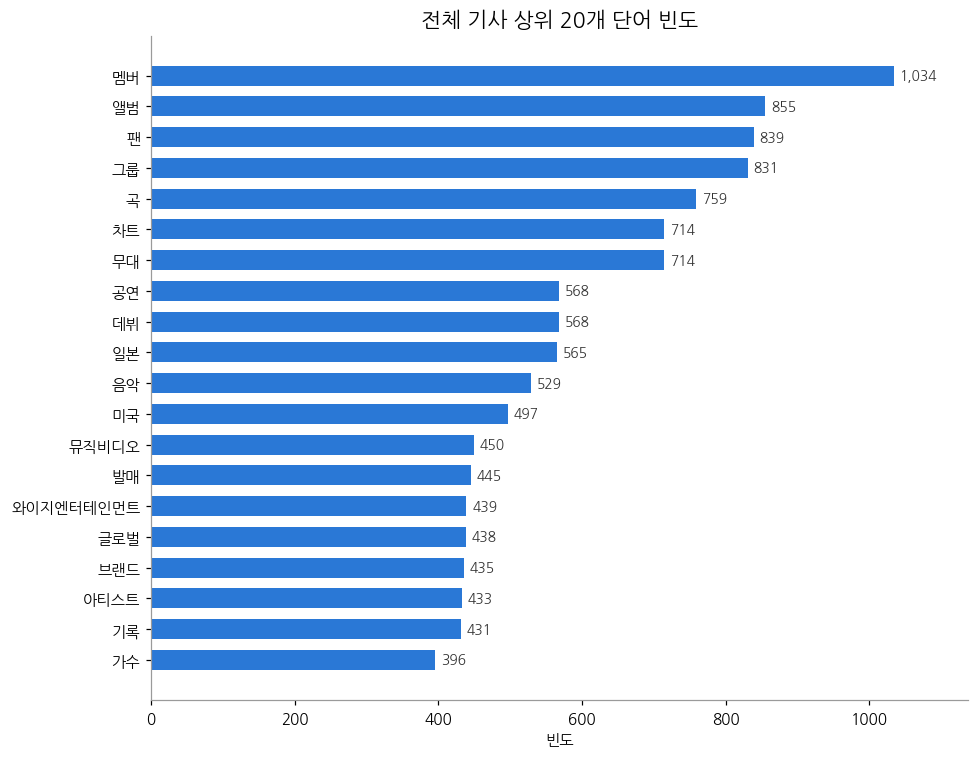

In [8]:
word_count = Counter(t for ts in df['clean'] for t in ts)
top20 = word_count.most_common(20)
print(top20)

words, freqs = zip(*top20)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(words[::-1], freqs[::-1], color='#2a78d6', height=0.65)
for i, v in enumerate(freqs[::-1]):
    ax.text(v + 8, i, f'{v:,}', va='center', fontsize=9, color='#333')
ax.set_title('전체 기사 상위 20개 단어 빈도')
ax.set_xlabel('빈도')
ax.set_xlim(0, max(freqs) * 1.1)
plt.tight_layout()
plt.show()

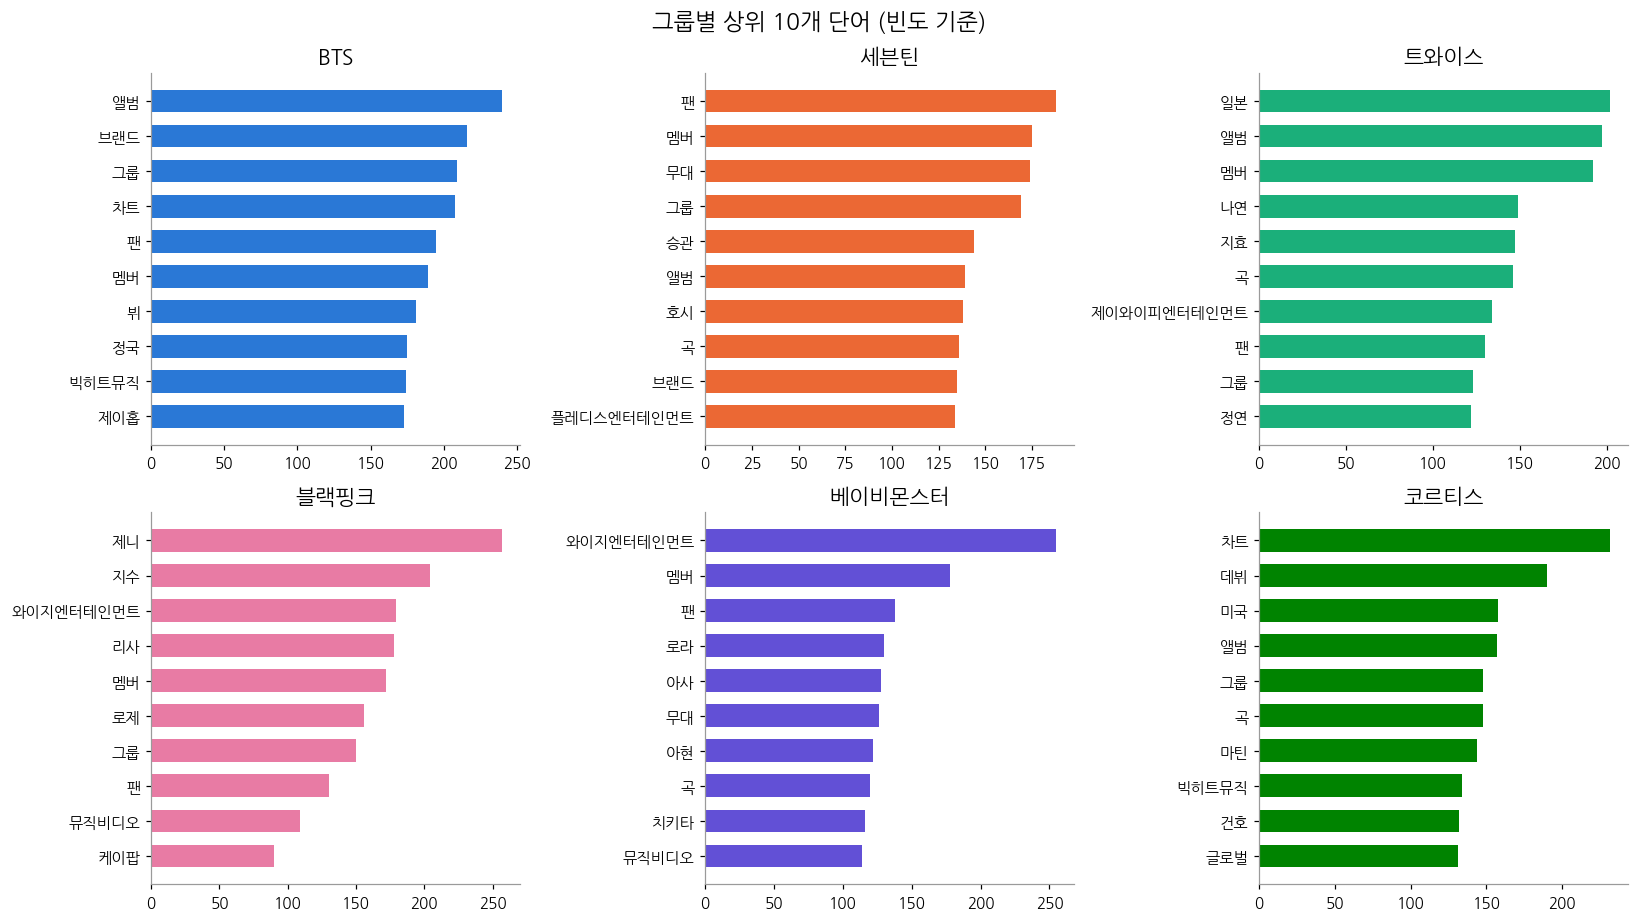

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, g in zip(axes.flat, GROUPS):
    c = Counter(t for ts in df.loc[df['group'] == g, 'clean'] for t in ts)
    w, f = zip(*c.most_common(10))
    ax.barh(w[::-1], f[::-1], color=GROUP_COLOR[g], height=0.65)
    ax.set_title(GROUP_LABEL[g])
    ax.tick_params(axis='y', labelsize=10)
fig.suptitle('그룹별 상위 10개 단어 (빈도 기준)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

고유 단어 3,030개 중 상위 100개(약 3.3%)가 전체 사용량의 35.7% 차지


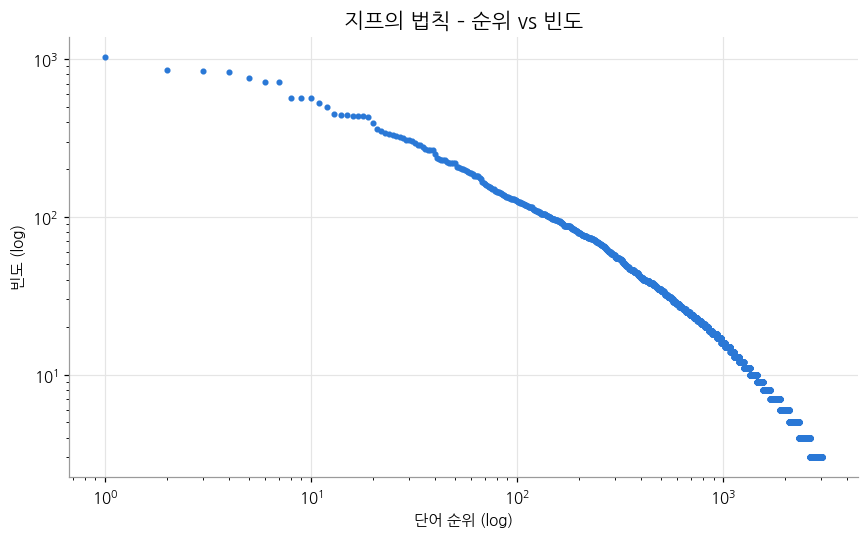

In [10]:
freq_sorted = np.array(sorted(word_count.values(), reverse=True))
rank = np.arange(1, len(freq_sorted) + 1)

top100_share = freq_sorted[:100].sum() / freq_sorted.sum()
print(f'고유 단어 {len(freq_sorted):,}개 중 상위 100개(약 {100/len(freq_sorted):.1%})가 '
      f'전체 사용량의 {top100_share:.1%} 차지')

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(rank, freq_sorted, marker='o', markersize=3, linewidth=0, color='#2a78d6')
ax.set_xlabel('단어 순위 (log)')
ax.set_ylabel('빈도 (log)')
ax.set_title('지프의 법칙 – 순위 vs 빈도')
ax.grid(True, which='major', color='#e5e5e5', linewidth=0.8)
plt.tight_layout()
plt.show()

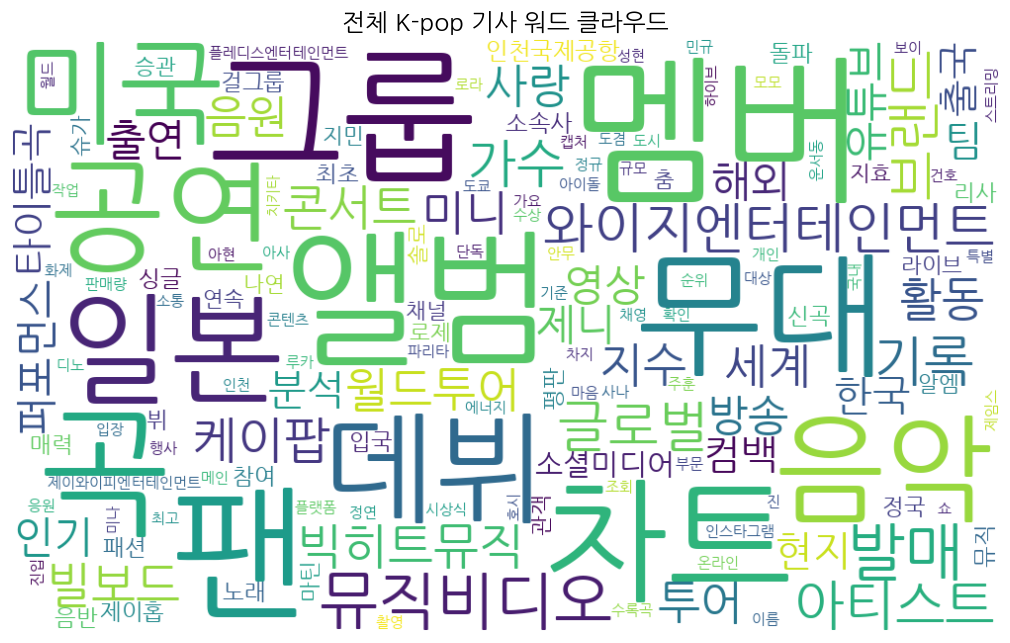

In [11]:
wc = WordCloud(font_path=font_path, width=1000, height=600,
               background_color='white', max_words=150,
               max_font_size=160, colormap='viridis', random_state=42)
wc.generate_from_frequencies(word_count)

plt.figure(figsize=(12, 7))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('전체 K-pop 기사 워드 클라우드', fontsize=16, fontweight='bold')
plt.show()

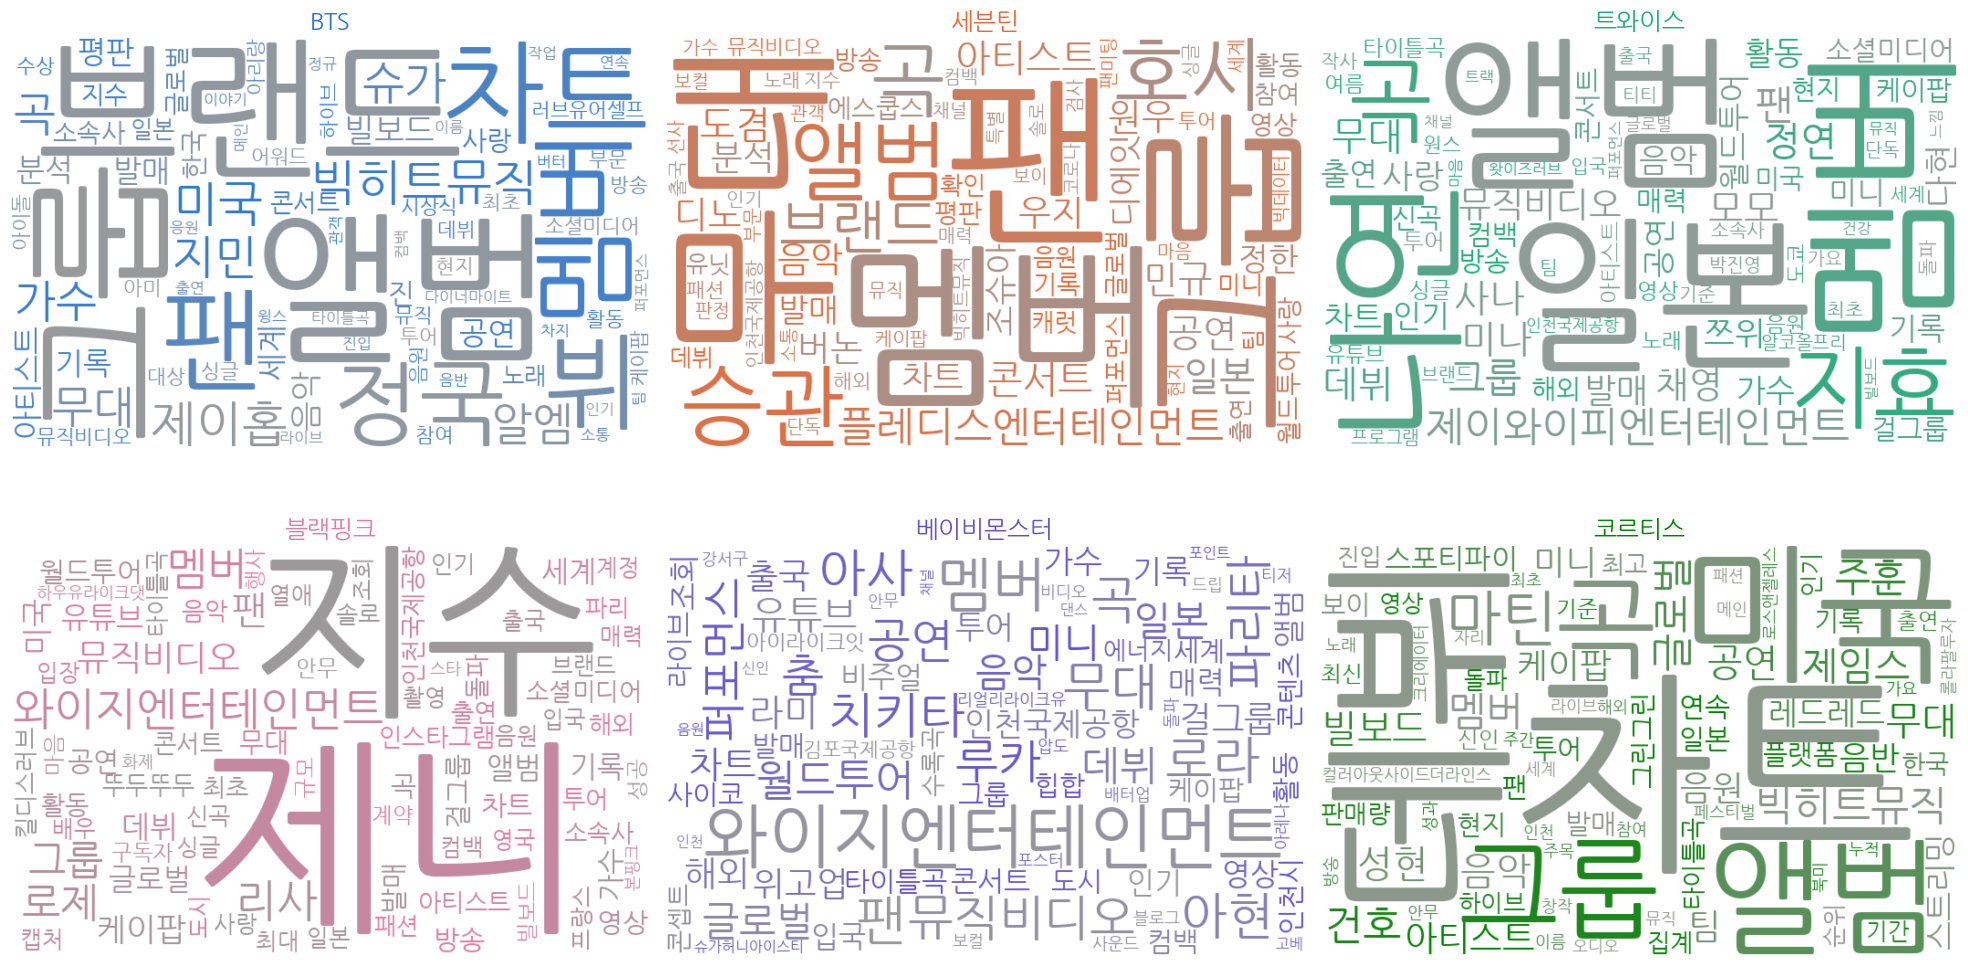

In [12]:
from matplotlib.colors import LinearSegmentedColormap

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, g in zip(axes.flat, GROUPS):
    freq = Counter(t for ts in df.loc[df['group'] == g, 'clean'] for t in ts)
    cmap = LinearSegmentedColormap.from_list(g, ['#9a9a9a', GROUP_COLOR[g]])
    wc_g = WordCloud(font_path=font_path, width=700, height=450,
                     background_color='white', max_words=80,
                     colormap=cmap, random_state=42).generate_from_frequencies(freq)
    ax.imshow(wc_g, interpolation='bilinear')
    ax.set_title(GROUP_LABEL[g], fontsize=16, fontweight='bold', color=GROUP_COLOR[g])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [13]:
from PIL import Image

MASK_FILE = 'mask.png'   # 업로드한 마스크 이미지 파일명
if os.path.exists(MASK_FILE):
    mask = np.array(Image.open(MASK_FILE).convert('L'))
    wc_mask = WordCloud(font_path=font_path, background_color='white',
                        mask=mask, contour_width=2, contour_color='#2a78d6',
                        max_words=200, random_state=42).generate_from_frequencies(word_count)
    wc_mask.to_file('kpop_wordcloud_mask.png')
    plt.figure(figsize=(9, 9))
    plt.imshow(wc_mask, interpolation='bilinear')
    plt.axis('off')
    plt.show()
else:
    print(f'{MASK_FILE} 이 없어서 건너뜀')

mask.png 이 없어서 건너뜀


In [14]:
docs = df['clean'].apply(' '.join)

tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None,
                        lowercase=False, min_df=3)
X_tfidf = tfidf.fit_transform(docs)
vocab = tfidf.get_feature_names_out()
print('TF-IDF 행렬 크기 (문서 수, 특성 수):', X_tfidf.shape)

group_tfidf = pd.DataFrame(
    {g: np.asarray(X_tfidf[(df['group'] == g).values].mean(axis=0)).ravel() for g in GROUPS},
    index=vocab)
group_tfidf.apply(lambda s: s.nlargest(10).index.tolist()).T

TF-IDF 행렬 크기 (문서 수, 특성 수): (1086, 3030)


,0,1,2,3,4,5,6,7,8,9
bts,뷔,제이홉,정국,슈가,지민,알엠,차트,앨범,진,미국
세븐틴,호시,승관,민규,도겸,버논,우지,조슈아,디노,원우,디에잇
트와이스,나연,모모,미나,사나,지효,정연,쯔위,일본,채영,다현
블랙핑크,제니,지수,로제,리사,와이지엔터테인먼트,멤버,인천국제공항,입국,가수,파리
베이비몬스터,아현,아사,로라,치키타,루카,파리타,와이지엔터테인먼트,라미,해외,멤버
코르티스,마틴,건호,주훈,차트,제임스,성현,데뷔,미국,빅히트뮤직,레드레드


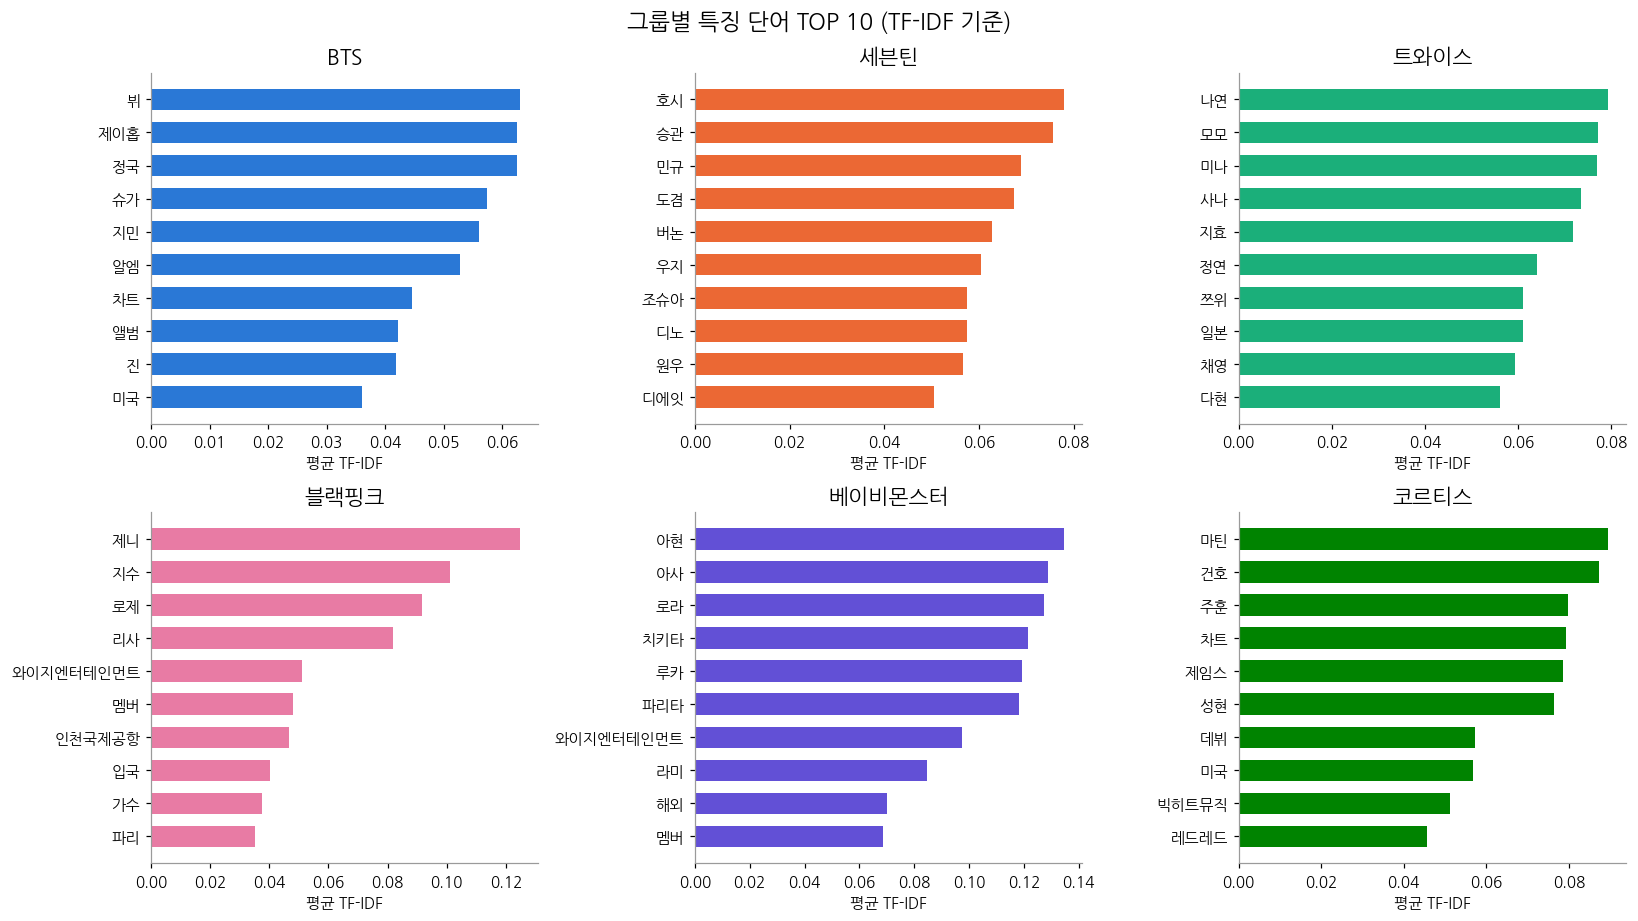

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, g in zip(axes.flat, GROUPS):
    top = group_tfidf[g].nlargest(10)[::-1]
    ax.barh(top.index, top.values, color=GROUP_COLOR[g], height=0.65)
    ax.set_title(GROUP_LABEL[g])
    ax.set_xlabel('평균 TF-IDF')
    ax.tick_params(axis='y', labelsize=10)
fig.suptitle('그룹별 특징 단어 TOP 10 (TF-IDF 기준)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

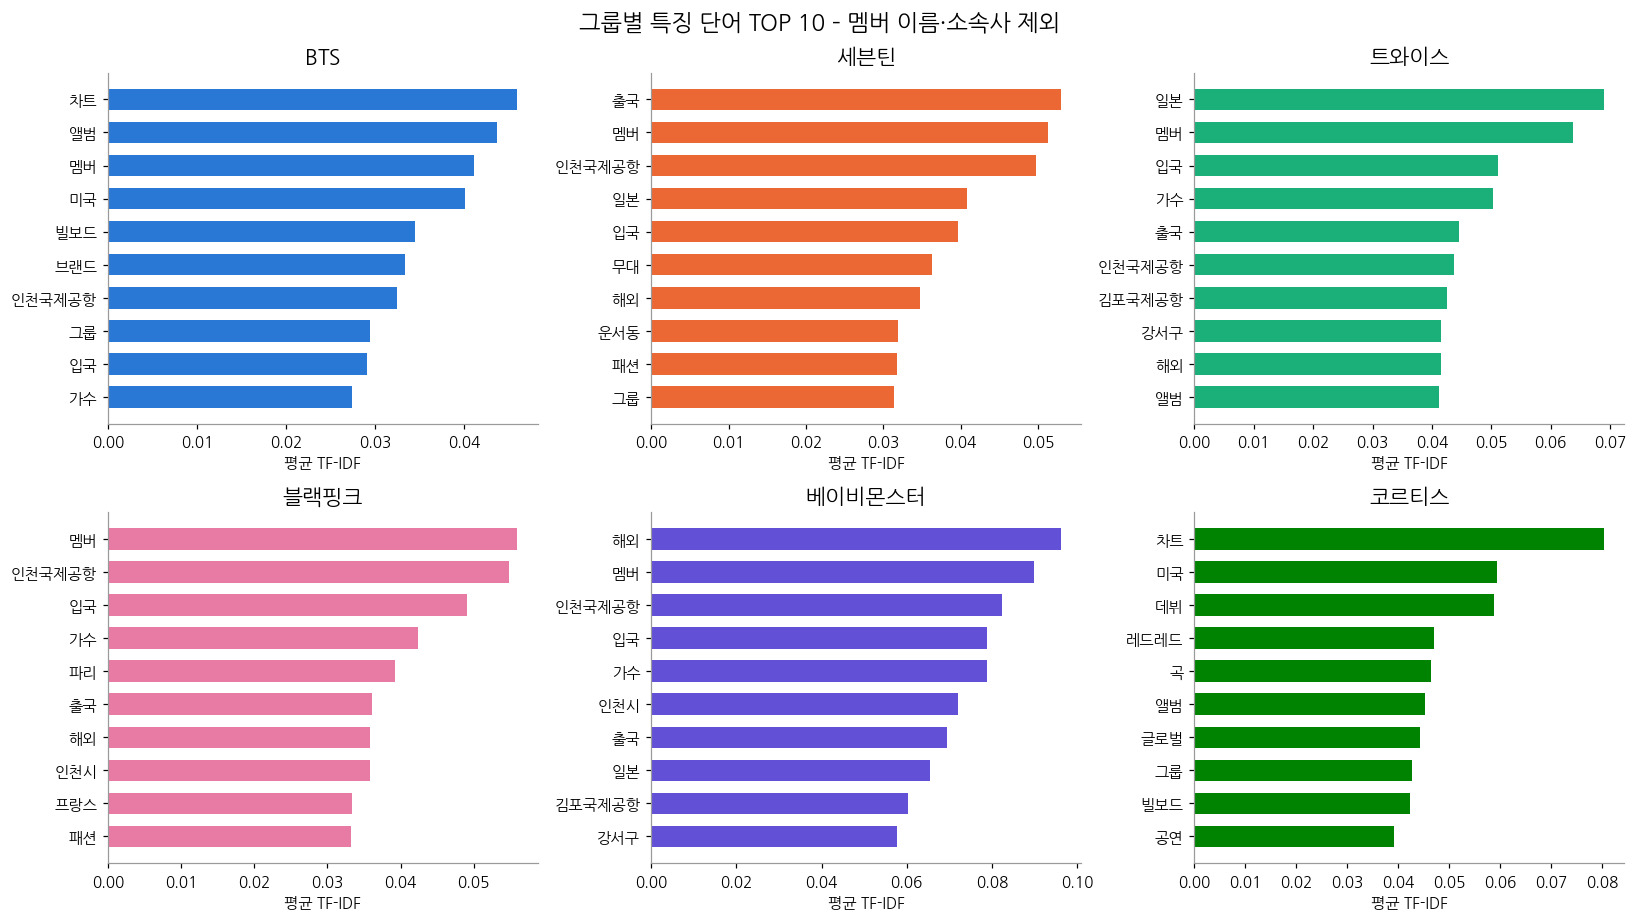

In [16]:
NAMES = set('''
알엠 슈가 제이홉 지민 뷔 진 정국
에스쿱스 정한 조슈아 준 호시 원우 우지 디에잇 민규 도겸 승관 버논 디노
나연 정연 모모 사나 지효 미나 다현 채영 쯔위
지수 제니 로제 리사
루카 파리타 아사 아현 라미 로라 치키타
마틴 제임스 주훈 성현 건호
빅히트뮤직 하이브 플레디스엔터테인먼트 제이와이피엔터테인먼트 와이지엔터테인먼트
방시혁 박진영 양현석
'''.split())

docs_topic = df['clean'].apply(lambda ts: ' '.join(t for t in ts if t not in NAMES))
tfidf_t = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=3)
X_topic = tfidf_t.fit_transform(docs_topic)
group_topic = pd.DataFrame(
    {g: np.asarray(X_topic[(df['group'] == g).values].mean(axis=0)).ravel() for g in GROUPS},
    index=tfidf_t.get_feature_names_out())

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, g in zip(axes.flat, GROUPS):
    top = group_topic[g].nlargest(10)[::-1]
    ax.barh(top.index, top.values, color=GROUP_COLOR[g], height=0.65)
    ax.set_title(GROUP_LABEL[g])
    ax.set_xlabel('평균 TF-IDF')
    ax.tick_params(axis='y', labelsize=10)
fig.suptitle('그룹별 특징 단어 TOP 10 – 멤버 이름·소속사 제외', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

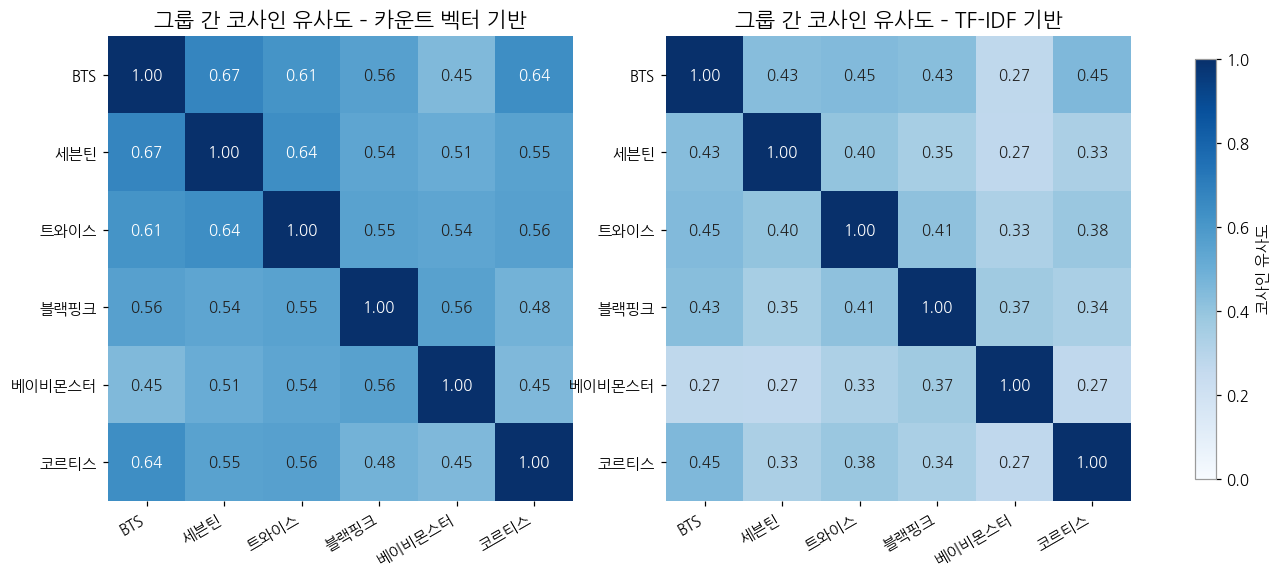

In [17]:
group_docs = [' '.join(' '.join(ts) for ts in df.loc[df['group'] == g, 'clean']) for g in GROUPS]

cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)
sim_count = cosine_similarity(cv.fit_transform(group_docs))

tv = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)
sim_tfidf = cosine_similarity(tv.fit_transform(group_docs))

labels = [GROUP_LABEL[g] for g in GROUPS]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, sim, title in zip(axes, [sim_count, sim_tfidf],
                          ['카운트 벡터 기반', 'TF-IDF 기반']):
    im = ax.imshow(sim, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(6), labels, rotation=30, ha='right')
    ax.set_yticks(range(6), labels)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f'{sim[i, j]:.2f}', ha='center', va='center', fontsize=10,
                    color='white' if sim[i, j] > 0.6 else '#222')
    ax.set_title(f'그룹 간 코사인 유사도 – {title}')
    ax.spines[:].set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label='코사인 유사도')
plt.show()

In [18]:
query_idx = 0                                   # 다른 번호로 바꿔서 실험해 보기
sims = cosine_similarity(X_tfidf[query_idx], X_tfidf).ravel()
order = sims.argsort()[::-1][1:6]               # 자기 자신(1.0) 제외

print('[기준 기사]', df.loc[query_idx, 'group'], '|', df.loc[query_idx, 'title'])
pd.DataFrame({'유사도': sims[order].round(3),
              '그룹': df.loc[order, 'group'].values,
              '날짜': df.loc[order, 'published_at'].dt.date.values,
              '제목': df.loc[order, 'title'].values})

[기준 기사] bts | [뮤직와치]시국 외면하지않는 아이돌, 방탄소년단 잘되는 이유 있구나


,유사도,그룹,날짜,제목
0,0.335,bts,2017-08-24,"방탄소년단 측 “9월 18일 컴백 확정, ‘LOVE YOURSELF-Her’ 발매”..."
1,0.323,bts,2019-06-03,눈물바다된 웸블리…방탄소년단 오열케한 6만 아미 깜짝 이벤트(종합①)
2,0.279,bts,2017-07-27,"방탄소년단, 12월 고척돔서 윙스투어 서울 파이널 개최(공식)"
3,0.270,bts,2017-07-24,방탄소년단 측 “9월 컴백 목표로 준비 중”(공식)
4,0.269,세븐틴,2020-07-06,"세븐틴, 미니 7집 ‘헹가래’ 활동 성료…밀리언셀러→각종 1위 석권"


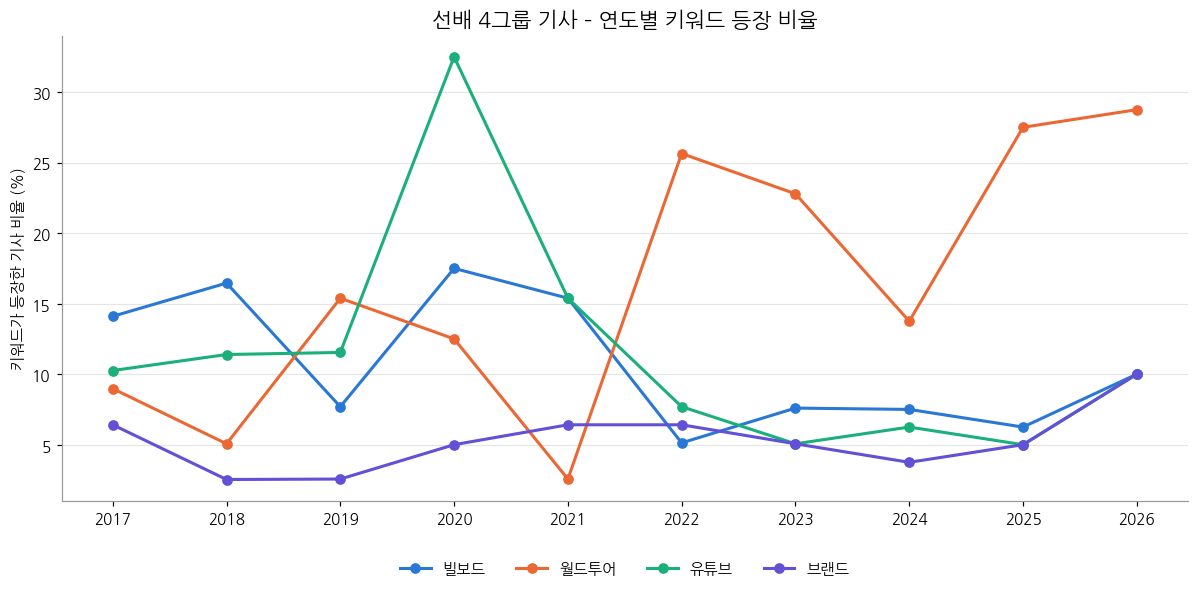

,빌보드,월드투어,유튜브,브랜드
year,,,,
2017,14.1,9.0,10.3,6.4
2018,16.5,5.1,11.4,2.5
2019,7.7,15.4,11.5,2.6
2020,17.5,12.5,32.5,5.0
2021,15.4,2.6,15.4,6.4
2022,5.1,25.6,7.7,6.4
2023,7.6,22.8,5.1,5.1
2024,7.5,13.8,6.2,3.8
2025,6.2,27.5,5.0,5.0


In [19]:
SENIOR = ['bts', '세븐틴', '트와이스', '블랙핑크']
KEYWORDS = ['빌보드', '월드투어', '유튜브', '브랜드']
KW_COLOR = ['#2a78d6', '#eb6834', '#1baf7a', '#6250d6']

sub = df[df['group'].isin(SENIOR)]
trend = pd.DataFrame({kw: sub.groupby('year')['clean'].apply(lambda s: s.apply(lambda ts: kw in ts).mean())
                      for kw in KEYWORDS}) * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
for kw, c in zip(KEYWORDS, KW_COLOR):
    ax.plot(trend.index, trend[kw], color=c, linewidth=2, marker='o', markersize=6, label=kw)
ax.set_xticks(trend.index)
ax.set_ylabel('키워드가 등장한 기사 비율 (%)')
ax.set_title('선배 4그룹 기사 – 연도별 키워드 등장 비율')
ax.grid(axis='y', color='#e5e5e5')
ax.legend(frameon=False, loc='upper center', ncol=4, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()
trend.round(1)